# Health - analyse

On part des tables nettoyées (`health_clean/`), sans hypothèse de départ : on cherche ce qui sort de l'ordinaire, puis on vérifie avec une autre source.

## 1. Chargement

In [1]:
import re
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

D = "health_clean/"
pat = pd.read_csv(D + "patient_administration.csv", parse_dates=["date_of_birth"])
enc = pd.read_csv(D + "clinical_encounters.csv")
obs = pd.read_csv(D + "clinical_observations.csv")
notes = pd.read_csv(D + "clinical_notes.csv")
rec = pd.read_csv(D + "cardiac_recordings.csv")
sig = pd.read_csv(D + "cardiac_signal_samples.csv")

## 2. Notes : trouver celles qui ne sont pas des modèles

La plupart des titres sont numérotés ("Clinical Summary 03") et semblent générés. Pour chaque note, on calcule la part de phrases qu'on ne retrouve dans aucune autre note.

In [2]:
sentences = notes["text"].str.split(r"(?<=\.)\s+")
counts = Counter(s.strip() for doc in sentences for s in doc)
notes["unique_share"] = sentences.apply(lambda doc: np.mean([counts[s.strip()] == 1 for s in doc]))

special = notes[notes["unique_share"] > 0.5]
print(special[["document_id", "patient_number", "title"]])
for t in special["text"]:
    print("\n#####\n", t)

# noms propres cités dans toutes les notes
print(Counter(n for t in notes["text"] for n in re.findall(r"\b[A-Z][a-z]+ [A-Z][a-z]+\b", t)))

  document_id patient_number  \
0  CLN-510027      PAT-31065   
1  CLN-510055      PAT-31115   
2  CLN-510025      PAT-31065   
3  CLN-510064      PAT-31012   

                                               title  
0                   Targeted Thoracic Imaging Review  
1    Consultation on Recurrent Capture Discrepancies  
2  Restricted Phenotype and Public-Identity Resol...  
3                   Persistent Multisystem Follow-up  

#####
 INDICATION
Review of recurrent discordance between peripheral pulse measurements and apical recordings in a restricted patient, with comparison to the prior rhythm study.

TECHNIQUE
Targeted thoracic ultrasound and synchronized surface recording were performed in two acoustic windows. Device quality was acceptable. The study was repeated after repositioning because the initial waveform contained motion artefact.

FINDINGS
Two spatially distinct zones of contractile motion are visible. The dominant left-sided source follows the peripheral pulse. A sec

## 3. Mesures : clustering des patients

Une ligne par patient (moyenne de chaque type de mesure), toutes les variables standardisées, k-means avec k=3.

In [3]:
feat = obs.pivot_table(index="patient_number", columns="observation_code", values="numeric_value", aggfunc="mean")
X = StandardScaler().fit_transform(feat.fillna(feat.median()))
feat["cluster"] = KMeans(3, n_init=10, random_state=0).fit_predict(X)
print(feat["cluster"].value_counts())

small = feat["cluster"].value_counts().idxmin()
group = feat[feat["cluster"] == small].index
profile = pd.DataFrame(X, index=feat.index, columns=feat.columns.drop("cluster")).groupby(feat["cluster"]).mean().T
profile.round(2).sort_values(small)

cluster
0    114
2    111
1     15
Name: count, dtype: int64


cluster,0,1,2
observation_code,,,
IDCONS,0.14,-2.55,0.20
CAMMATCH,0.20,-2.29,0.10
THERMQUAL,-0.04,-1.46,0.24
SYSBP,-0.20,-0.49,0.27
LEFTEYE,0.02,-0.28,0.02
RPULSE,-0.02,-0.27,0.06
GAITSYM,-0.03,-0.26,0.06
INFLAM,-0.43,-0.23,0.47
BIOAGE,-0.65,-0.22,0.70


## 4. Lien entre les notes et le groupe

In [4]:
print("notes uniques concernant le petit cluster :", special["patient_number"].isin(group).sum(), "/", len(special))
pat[pat["patient_number"].isin(group)][["patient_number", "family_name", "given_name", "date_of_birth", "occupation_text"]]

notes uniques concernant le petit cluster : 4 / 4


,patient_number,family_name,given_name,date_of_birth,occupation_text
0,PAT-31162,Varen,Eli,1962-04-19,corporate adviser
1,PAT-31040,Valen,Jonah,1972-06-12,research professional
2,PAT-31115,Oren,Nadia,1979-09-03,clinical specialist
3,PAT-31186,Kader,Soren,1969-02-11,corporate adviser
4,PAT-31215,Roe,Ilan,1976-07-07,research professional
5,PAT-31233,Ven,Mara,1983-05-23,research professional
6,PAT-31065,Hallen,Corin,1975-10-09,clinical specialist
7,PAT-31012,Sen,Amara,1981-08-16,research professional
8,PAT-31086,Veran,Niko,1973-01-29,corporate adviser
9,PAT-31037,Aran,Sel,1986-11-04,research professional


## 5. ECG : un patient du groupe et un patient normal

Avec un seul cœur, les pics des canaux A et B tombent au même moment.

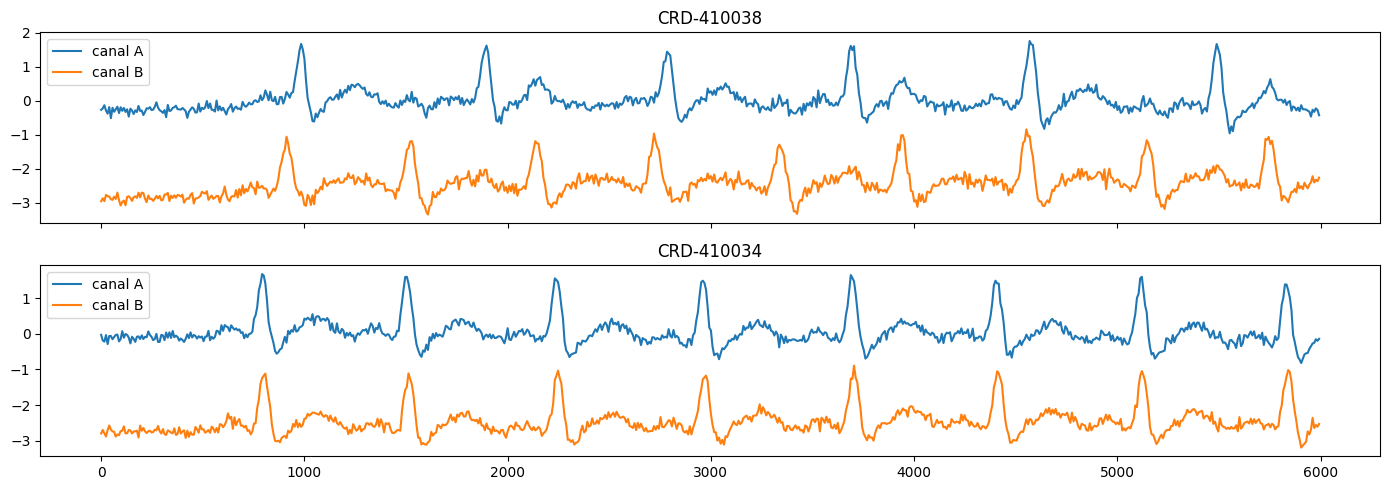

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(14, 5), sharex=True)
for ax, rid in zip(axes, ["CRD-410038", "CRD-410034"]):
    g = sig[(sig["recording_id"] == rid) & (sig["time_ms"] < 6000)]
    ax.plot(g["time_ms"], g["channel_a_normalized"], label="canal A")
    ax.plot(g["time_ms"], g["channel_b_normalized"] - 2.5, label="canal B")
    ax.set_title(rid); ax.legend()
plt.tight_layout()

## 6. ECG : désynchronisation des canaux sur tous les enregistrements

In [6]:
rows = []
for rid, g in sig.groupby("recording_id"):
    t = g["time_ms"].to_numpy()
    dur = (t[-1] - t[0]) / 1000
    peaks = {}
    for ch in "ab":
        x = g[f"channel_{ch}_normalized"].to_numpy() - g[f"channel_{ch}_normalized"].median()
        idx, _ = find_peaks(x, height=0.6 * np.percentile(x, 99.5), distance=int(400 / np.median(np.diff(t))))
        peaks[ch] = t[idx]
    offset = np.mean([np.abs(peaks["a"] - tb).min() for tb in peaks["b"]])
    rows.append({"recording_id": rid, "bpm_A": round(len(peaks["a"]) / dur * 60),
                 "bpm_B": round(len(peaks["b"]) / dur * 60), "decalage_ms": round(offset)})

ecg = pd.DataFrame(rows).merge(rec[["recording_id", "patient_number"]])
ecg["desynchronise"] = ecg["decalage_ms"] > 60
print(pd.crosstab(ecg["patient_number"].isin(group).rename("groupe_atypique"), ecg["desynchronise"]))
ecg.sort_values("decalage_ms", ascending=False).head(10)

desynchronise    False  True 
groupe_atypique              
False               29      6
True                 1      8


,recording_id,bpm_A,bpm_B,decalage_ms,patient_number,desynchronise
30,CRD-410031,65,85,238,PAT-31162,True
4,CRD-410005,66,98,227,PAT-31065,True
37,CRD-410038,65,98,219,PAT-31065,True
18,CRD-410019,70,86,214,PAT-31162,True
21,CRD-410022,68,92,203,PAT-31037,True
9,CRD-410010,70,70,193,PAT-31076,True
24,CRD-410025,75,95,192,PAT-31040,True
13,CRD-410014,73,87,191,PAT-31233,True
15,CRD-410016,84,78,180,PAT-31115,True
40,CRD-410041,65,80,170,PAT-31155,True


## 7. Identifier le patient cité dans la note

La note relie un patient au nom trouvé en partie 2, par des attributs combinés (naissance, région, orientation "executive health"). On récupère ces attributs dans les registres publics.

In [7]:
off = pd.read_csv("../public_records/officer_filings.csv", dtype=str)
print(off[off["full_name"].str.contains("Elias Voss", na=False)][["full_name", "birth_year_or_age_band", "role_title"]])

pat["birth_year"] = pat["date_of_birth"].dt.year
execs = enc.loc[enc["referral_source"] == "executive health office", "patient_number"].unique()
cand = pat[(pat["home_region"] == "valenne republic") & pat["birth_year"].between(1956, 1966)
           & pat["patient_number"].isin(execs)].copy()
cand["groupe_atypique"] = cand["patient_number"].isin(group)
cand["ecg_desynchronise"] = cand["patient_number"].isin(ecg.loc[ecg["desynchronise"], "patient_number"])
cand[["patient_number", "family_name", "given_name", "date_of_birth", "occupation_text", "groupe_atypique", "ecg_desynchronise"]]

        full_name birth_year_or_age_band  \
3  Dr. Elias Voss                   1961   

                                 role_title  
3  Executive chair of Meridian BioLogistics  


,patient_number,family_name,given_name,date_of_birth,occupation_text,groupe_atypique,ecg_desynchronise
0,PAT-31162,Varen,Eli,1962-04-19,corporate adviser,True,True
15,PAT-31183,Solva,Adrienne,1958-03-16,executive director of ardena capital union,False,False
27,PAT-31054,Zorin,Miran,1958-04-04,campaign coordinator,False,False
29,PAT-31231,Palen,Ravin,1963-02-08,clinical research scientist,False,False
31,PAT-31172,Yorin,Zoren,1964-05-19,grant officer,False,False
48,PAT-31095,Serin,Yorin,1962-02-03,investigative reporter,False,False
94,PAT-31078,Orsen,Hana,1965-08-04,transport worker,False,False
158,PAT-31227,Uren,Zoren,1959-02-08,technician,False,False
159,PAT-31121,Koral,Kira,1964-09-21,teacher,False,False
